In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris

# 1. Load the Iris dataset directly from sklearn as a pandas DataFrame
iris = load_iris(as_frame=True)
df = iris.frame

# Map target integers to species names for better readability in plots and reports
df['species'] = df['target'].map(
    {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
)

# 2. Inspect Dataset Structure and Hygiene
print(f'Dataset Shape: {df.shape}')
print('\nData Types:\n', df.dtypes)
print('\nMissing Values:\n', df.isnull().sum())
print('\nDescriptive Statistics:\n', df.describe())

/home/f8450f7e-39c0-48a4-b9a7-9e8e1060928e/.local/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/f8450f7e-39c0-48a4-b9a7-9e8e1060928e/.local/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Dataset Shape: (150, 6)

Data Types:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object

Missing Values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Descriptive Statistics:
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.9000

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/

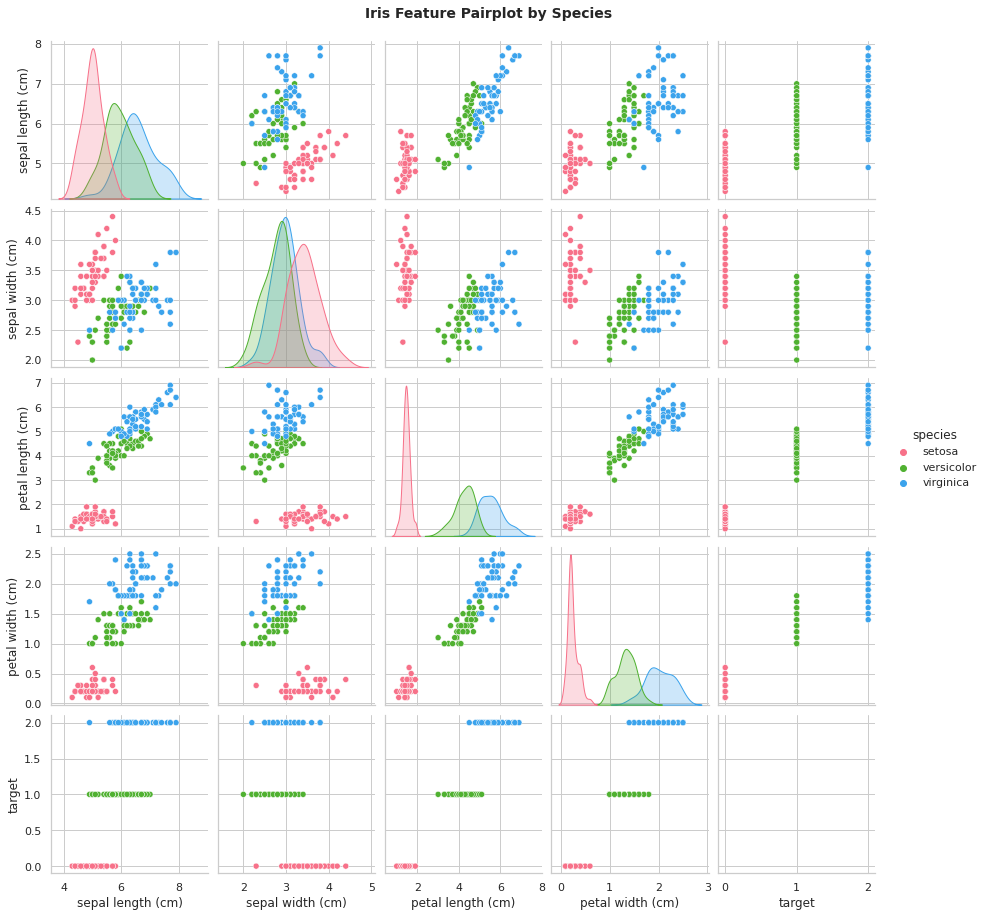

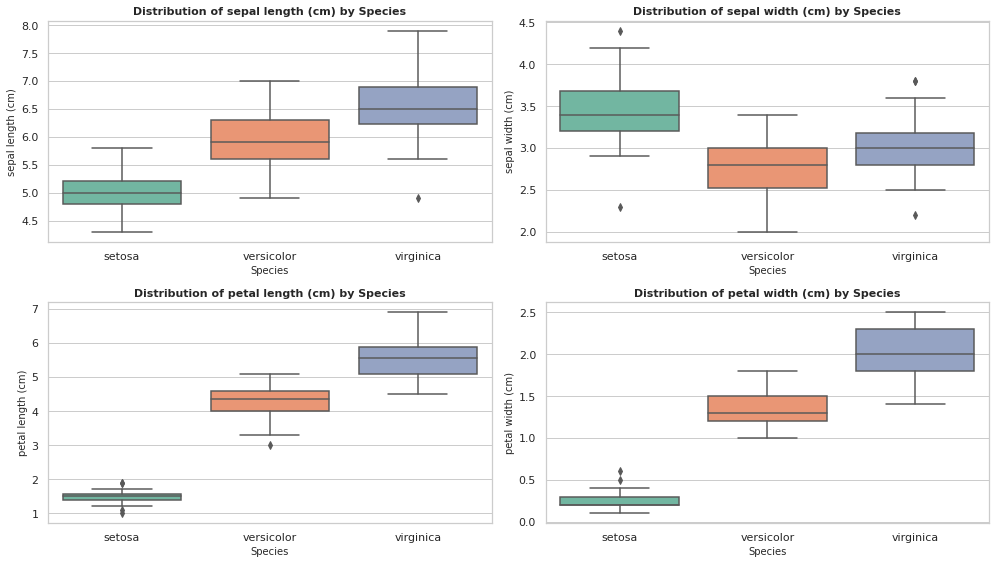

In [3]:
import pandas as pd

# Monkeypatch pandas option_context to handle seaborn's deprecated call safely
_original_option_context = pd.option_context


class _SafeOptionContext:

  def __init__(self, *args):
    filtered_args = []
    i = 0
    while i < len(args):
      if args[i] == 'mode.use_inf_as_null':
        i += 2
      else:
        filtered_args.append(args[i])
        filtered_args.append(args[i + 1])
        i += 2

    self.ctx = (
        _original_option_context(*filtered_args) if filtered_args else None
    )

  def __enter__(self):
    if self.ctx:
      return self.ctx.__enter__()

  def __exit__(self, exc_type, exc_val, exc_tb):
    if self.ctx:
      return self.ctx.__exit__(exc_type, exc_val, exc_tb)


pd.option_context = _SafeOptionContext

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Load data
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map(
    {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
)

# Set seaborn styling
sns.set_theme(style='whitegrid')

# 1. Pairplot
sns.pairplot(df, hue='species', palette='husl', diag_kind='kde', height=2.5)
plt.suptitle('Iris Feature Pairplot by Species', y=1.02, fontsize=14, fontweight='bold')
plt.show()

# 2. Box Plots for each feature across species
plt.figure(figsize=(14, 8))
features = [
    'sepal length (cm)',
    'sepal width (cm)',
    'petal length (cm)',
    'petal width (cm)',
]

for i, feature in enumerate(features, 1):
  plt.subplot(2, 2, i)
  sns.boxplot(x='species', y=feature, data=df, palette='Set2')
  plt.title(f'Distribution of {feature} by Species', fontsize=11, fontweight='bold')
  plt.xlabel('Species', fontsize=10)
  plt.ylabel(feature, fontsize=10)

plt.tight_layout()
plt.show()

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/

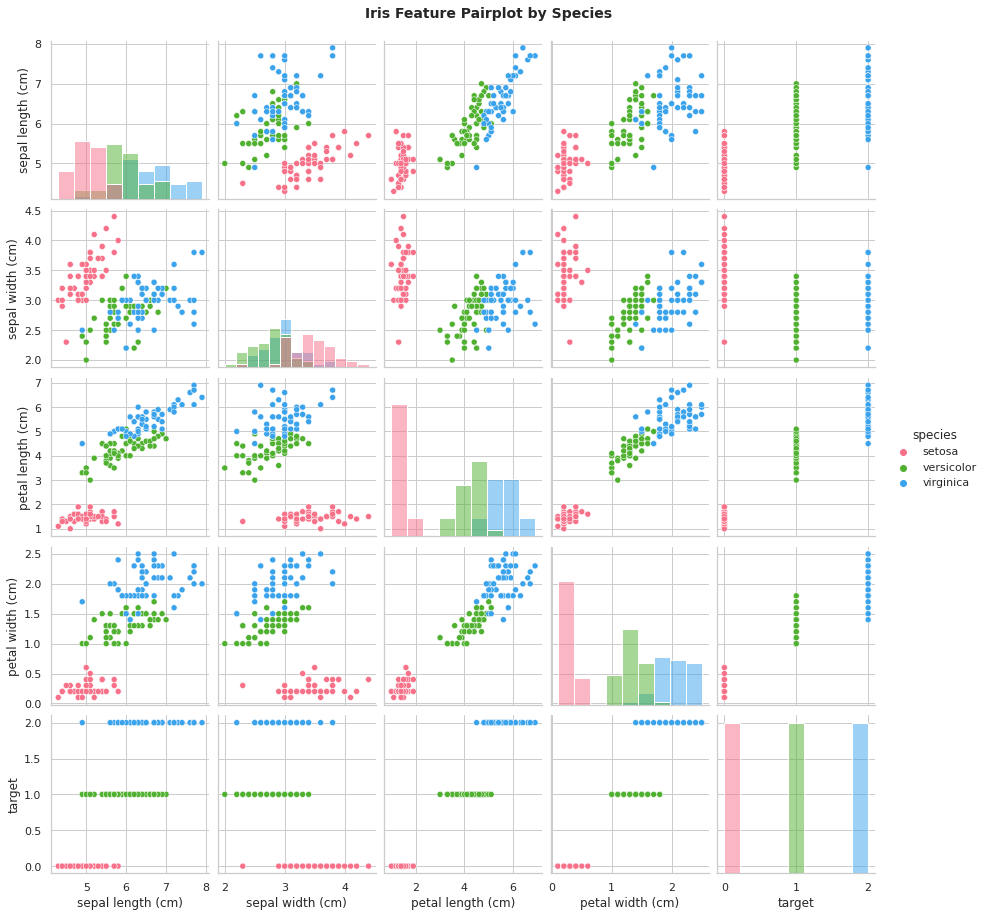

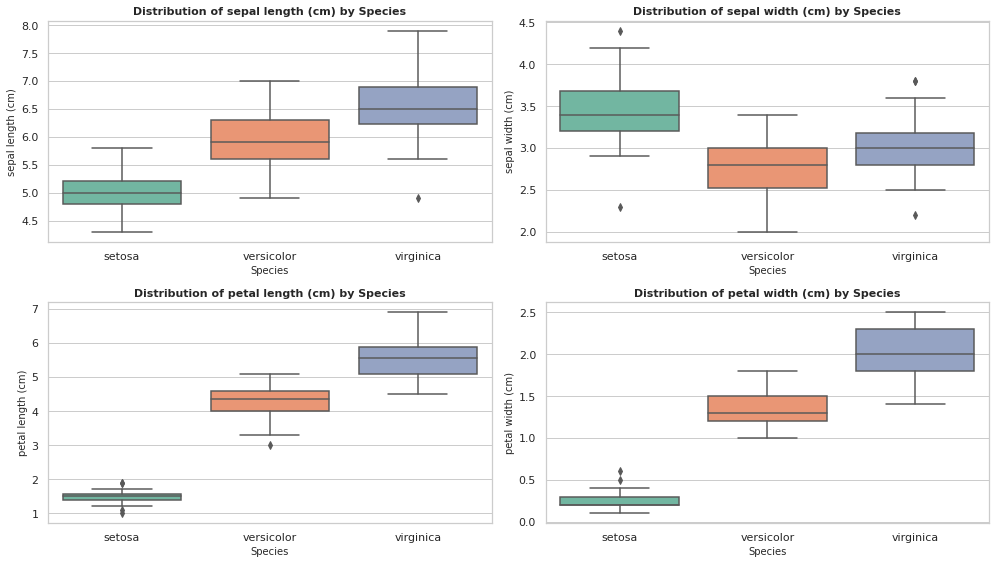

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Define Features (X) and Target (y)
# Drop non-feature columns like 'target' or 'species', use only the 4 physical measurements
X = df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']]
y = df['target']

# 2. Train/Test Split (80% train, 20% test with stratification to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set shape: {X_train.shape}')
print(f'Testing set shape: {X_test.shape}\n')

# 3. Initialize Classifiers
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# 4. Train and Evaluate Each Model
model_performance = {}

for name, clf in classifiers.items():
  print(f'================ {name} ================')
  # Train model
  clf.fit(X_train, y_train)

  # Predict on test set
  y_pred = clf.predict(X_test)

  # Calculate metrics
  acc = accuracy_score(y_test, y_pred)
  model_performance[name] = acc

  print(f'Accuracy: {acc * 100:.2f}%\n')
  print('Classification Report:')
  print(
      classification_report(
          y_test,
          y_pred,
          target_names=iris.target_names
      )
  )
  print('Confusion Matrix:')
  print(confusion_matrix(y_test, y_pred))
  print('\n')

# 5. Summary Comparison
print('================ Summary ================')
best_model = max(model_performance, key=model_performance.get)
for name, acc in model_performance.items():
  print(f'{name}: {acc * 100:.2f}%')
print(f'\n🏆 Best Performing Model: {best_model}')

Training set shape: (120, 4)
Testing set shape: (30, 4)

================ Logistic Regression ================
Accuracy: 96.67%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


================ K-Nearest Neighbors (KNN) ================
Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00   